<a href="https://colab.research.google.com/github/varshini-188/Machine-Learning/blob/main/16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Setup and Dataset Creation
We will start by importing the necessary libraries and generating a synthetic classification dataset using `scikit-learn`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Generate a synthetic 2-class classification dataset
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=8,
    n_redundant=2,
    random_state=42
)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Scale the features (important for algorithms like SVM and Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Testing set shape: {X_test_scaled.shape}")

Training set shape: (750, 10)
Testing set shape: (250, 10)


### 2. Model Training and Evaluation
Next, we define several classification algorithms, train them on our training subset, and gather evaluation metrics (Accuracy, Precision, Recall, and F1-score) using the test set.

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Initialize models
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Support Vector Machine': SVC(random_state=42)
}

# Dictionary to store performance metrics
results = []

# Train and evaluate each model
for model_name, model in models.items():
    # Fit model
    model.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model.predict(X_test_scaled)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

# Convert results to DataFrame for easy visualization
df_results = pd.DataFrame(results)
display(df_results)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.696,0.664179,0.741667,0.700787
1,Decision Tree,0.816,0.808333,0.808333,0.808333
2,Random Forest,0.884,0.852713,0.916667,0.883534
3,Support Vector Machine,0.924,0.891473,0.958333,0.923695


### 3. Visual Performance Comparison
Let's visualize the metrics to easily identify the best-performing algorithm.

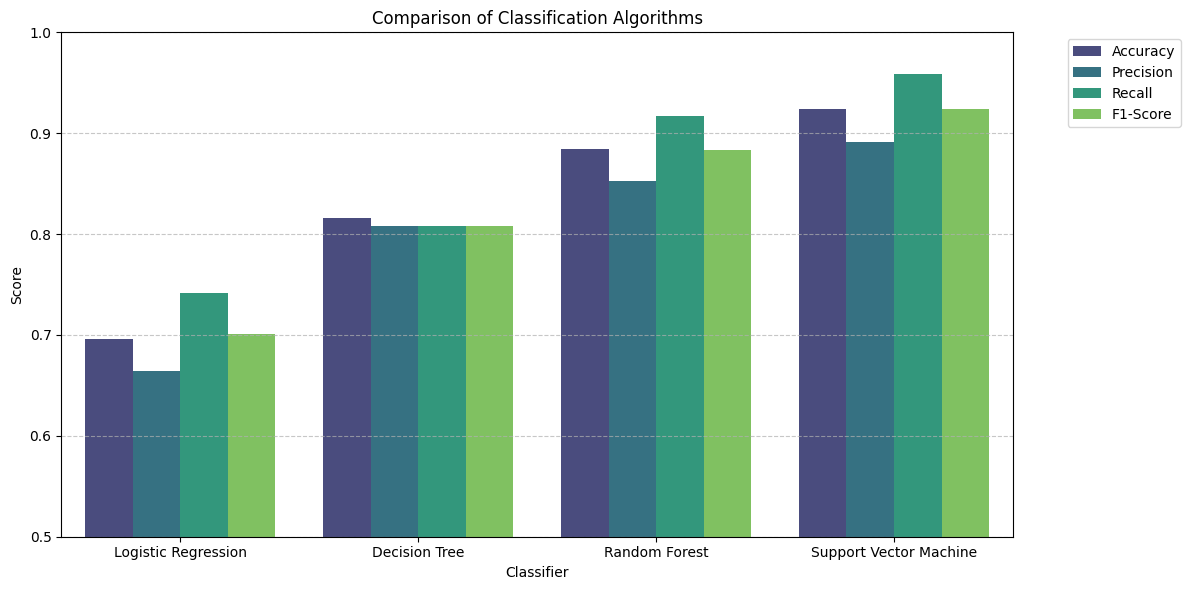

In [3]:
# Melt the DataFrame to make it suitable for seaborn barplot
df_melted = pd.melt(df_results, id_vars='Model', var_name='Metric', value_name='Value')

plt.figure(figsize=(12, 6))
sns.barplot(x='Model', y='Value', hue='Metric', data=df_melted, palette='viridis')
plt.title('Comparison of Classification Algorithms')
plt.ylim(0.5, 1.0)  # Zoom in on the differences
plt.ylabel('Score')
plt.xlabel('Classifier')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()